In [6]:
import re
from pathlib import Path
import time
import matplotlib.pyplot as plt
import numpy as np
from mmwave.dsp.range_processing import range_processing
import functools

In [7]:
ANT_NUM = 4
ADC_SAMPLES = 256
CHIRP_LOOPS = 2
SAMPLES_PER_FRAME = ADC_SAMPLES * CHIRP_LOOPS  # 512
FFT_SIZE = 512  # para.FFTSize in f_Parameter.m
N_FRAMES = 20 * 60 * 5  # para.datalength
TOKEN = re.compile(rb"([+-]?\d+)([+-]\d+)i")

In [8]:
def log(func):
    @functools.wraps(func)
    def wrapper(*args, **kw):
        start = time.perf_counter()
        result = func(*args, **kw)
        end = time.perf_counter()
        print(f"{func.__name__}() 用时:{end - start:.3f}s")
        return result
    return wrapper

In [9]:
@log
def default_rawdata_dir():
    """Locate Rawdata without requiring ``__file__`` (unset in notebooks).

    The notebook kernel often starts in the home directory, so a relative
    ``data/...`` path becomes ``~/data/...`` and misses this project.
    """
    relative = Path("data") / "Children Dataset" / "FMCW Radar" / "Rawdata"
    from_data_dir = Path("Children Dataset") / "FMCW Radar" / "Rawdata"
    roots = [Path.cwd(), Path.home()]
    script = globals().get("__file__")
    if script:
        roots.insert(0, Path(script).resolve().parents[2])
    candidates = []
    for root in roots:
        candidates.append(root / relative)
        candidates.append(root / from_data_dir)
        for parent in root.parents:
            candidates.append(parent / relative)
        try:
            children = [child for child in root.iterdir() if child.is_dir()]
        except OSError:
            children = []
        for child in children:
            candidates.append(child / relative)
    for path in candidates:
        if path.is_dir():
            return path
    raise FileNotFoundError(
        "Rawdata directory not found. Pass the CSV path explicitly, for example "
        "Path('/Users/fuzzybird/养老监护/data/Children Dataset/FMCW Radar/Rawdata/Rawdata_1.csv')"
    )

In [10]:
@log
def load_rawdata(path, n_frames):
    """Read ``n_frames`` from a Rawdata CSV into shape (4, 512, n_frames)."""
    n_samples = n_frames * SAMPLES_PER_FRAME
    antennas = np.empty((ANT_NUM, n_samples), dtype=np.complex128)
    with path.open("rb") as handle:
        for antenna in range(ANT_NUM):
            line = handle.readline()
            if not line:
                raise ValueError(f"{path} ended before antenna {antenna + 1}")
            tokens = line.split(b",", n_samples)[:n_samples]
            if len(tokens) < n_samples:
                raise ValueError(
                    f"{path} antenna {antenna + 1} has {len(tokens)} samples, "
                    f"need {n_samples}"
                )
            for index, token in enumerate(tokens):
                match = TOKEN.fullmatch(token.strip())
                if match is None:
                    raise ValueError(
                        f"unrecognized sample on antenna {antenna + 1}: {token[:40]!r}"
                    )
                real = int(match.group(1))
                imag = int(match.group(2))
                antennas[antenna, index] = real + 1j * imag
    # File order is frame-major: frame 0's 512 samples, then frame 1, ...
    return antennas.reshape(ANT_NUM, n_frames, SAMPLES_PER_FRAME).transpose(0, 2, 1)

In [20]:
@log
def range_fft(raw):
    """Match ``f_RangeFFT``: FFT along the 512-sample axis, length 1024.

    ``raw`` is (antennas, samples, frames). The result is
    (antennas, fft_size, frames), the same layout as the MATLAB output.
    """
    if raw.shape[1] != SAMPLES_PER_FRAME:
        raise ValueError(f"expected {SAMPLES_PER_FRAME} samples per frame, got {raw.shape[1]}")
    padded = np.pad(raw, ((0, 0), (0, FFT_SIZE - SAMPLES_PER_FRAME), (0, 0)))
    # range_processing transforms axis -1 and does not take an nfft argument.
    adc = np.transpose(padded, (2, 0, 1))
    cube = range_processing(adc)
    return np.transpose(cube, (1, 2, 0))

In [21]:
@log
def mti(range_fft_out, alpha=0.01):
    """Match ``f_MTI``: subtract a slow clutter estimate along frames.

    ``range_fft_out`` has shape (antennas, fft_size, frames), the same
    layout as ``f_RangeFFT``. The MATLAB loop starts at frame 2, so frame 0
    of both the clutter map and the output stays zero, and that frame of the
    input is not used. Each later frame updates

        clutter = alpha * x + (1 - alpha) * clutter
        y = x[:fft_size/2] - clutter[:fft_size/2]

    The return value has shape (antennas, fft_size/2, frames).
    """
    if not 0.0 < alpha <= 1.0:
        raise ValueError(f"alpha must be in (0, 1], got {alpha}")
    n_bins = range_fft_out.shape[1]
    if n_bins % 2 != 0:
        raise ValueError(f"fft_size must be even, got {n_bins}")
    half = n_bins // 2
    clutter = np.zeros_like(range_fft_out)
    output = np.zeros(
        (range_fft_out.shape[0], half, range_fft_out.shape[2]),
        dtype=range_fft_out.dtype,
    )
    one_minus_alpha = 1.0 - alpha
    for frame in range(1, range_fft_out.shape[2]):
        clutter[:, :, frame] = (
            alpha * range_fft_out[:, :, frame]
            + one_minus_alpha * clutter[:, :, frame - 1]
        )
        output[:, :, frame] = (
            range_fft_out[:, :half, frame] - clutter[:, :half, frame]
        )
    return output

In [22]:
def _magnitude_db(magnitude, reference):
    """20*log10(|x| / reference), with a floor so empty bins stay finite."""
    return 20.0 * np.log10(np.maximum(magnitude, 1e-12) / reference)

In [31]:
@log
def main():
    path = default_rawdata_dir()/"Rawdata_1.csv"
    n_frames = 20 * 30
    nfft = 1024
    ft = 512
    max_range_m = 1.0
    raw = load_rawdata(path, n_frames)

default_rawdata_dir() 用时:0.003s
load_rawdata() 用时:0.631s
range_fft() 用时:0.007s
mti() 用时:0.010s
antenna 0, range <= 1 m, after 5 s: mean -9.0 dB, peak at 0.00 m -22.5 dB
f_MTI first step max abs error: 7.276e-12


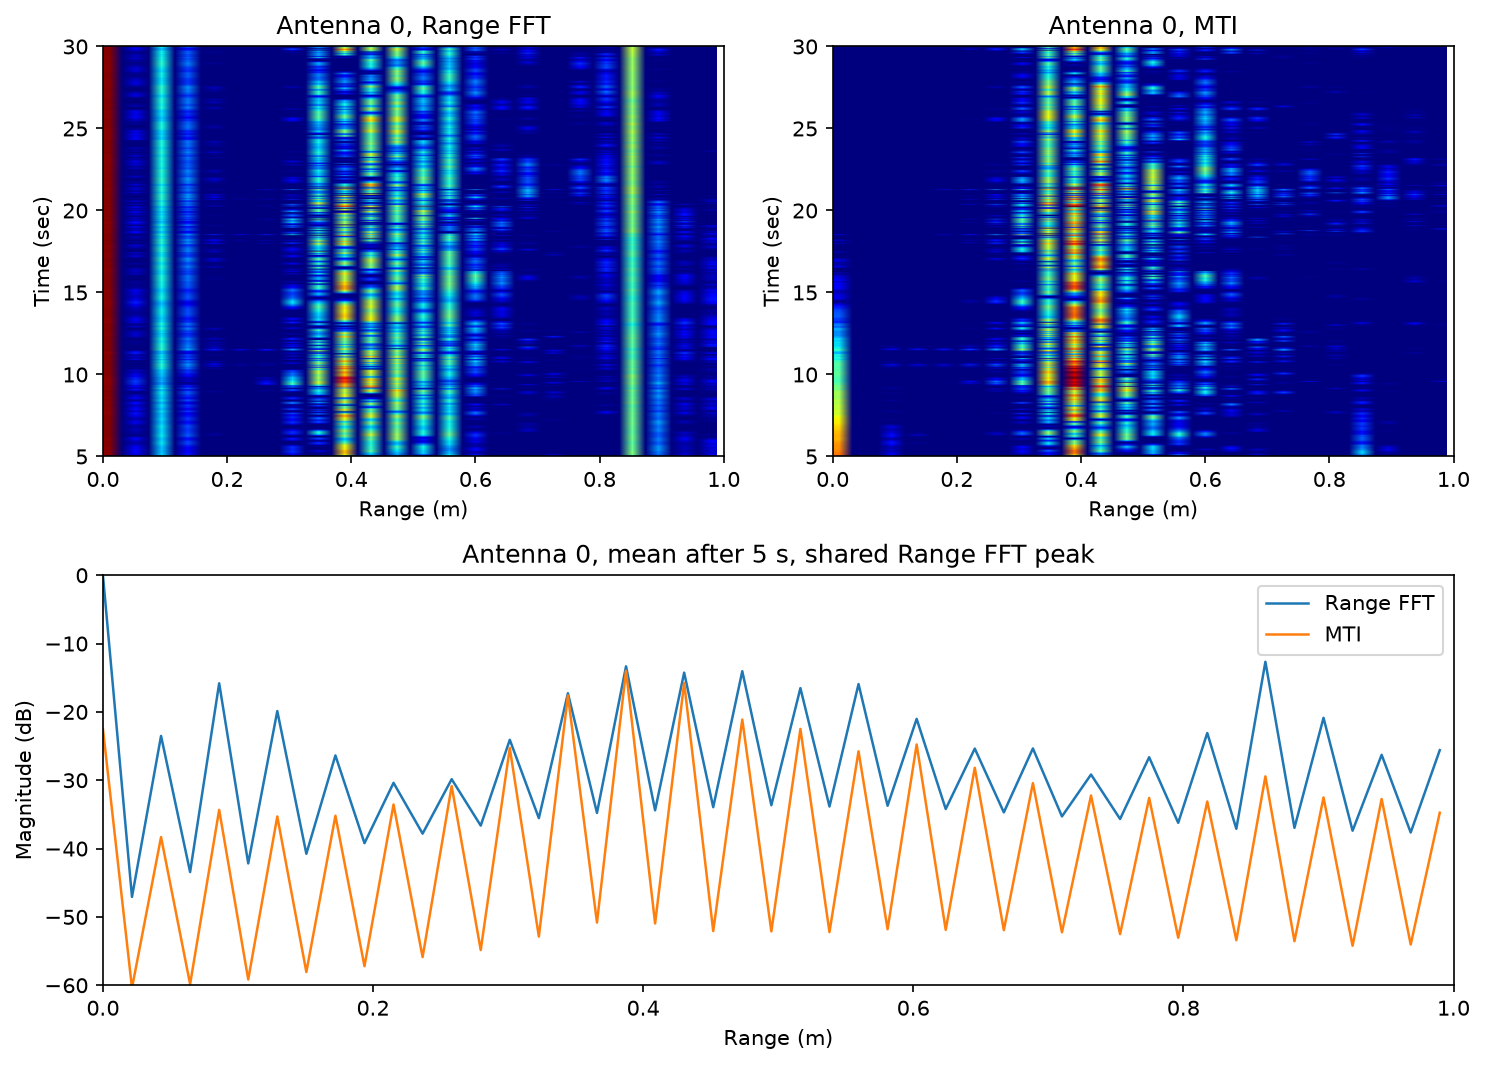

In [53]:
path = default_rawdata_dir()/"Rawdata_1.csv"
n_frames = 20 * 30
nfft = 512
ft = 512
max_range_m = 1.0
raw = load_rawdata(path, n_frames)
spectrum = range_fft(raw)
movement = mti(spectrum)
half = FFT_SIZE // 2
alpha = 0.01
first_step = (1.0 - alpha) * spectrum[:, :half, 1]
first_step_error = np.max(np.abs(movement[:, :, 1] - first_step))
if movement[:, :, 0].any() or first_step_error > 1e-6:
    raise RuntimeError(
        "MTI does not match f_MTI.m: "
        f"frame0 max {np.max(np.abs(movement[:, :, 0]))}, "
        f"first-step error {first_step_error}"
    )

settled = slice(100, None)  # f_MovementMeasure also drops the first 5 s
before = np.abs(spectrum[0, :half, settled])
after = np.abs(movement[0, :, settled])
visible = distance_m[:half] <= max_range_m
before_profile = before[visible].mean(axis=1)
after_profile = after[visible].mean(axis=1)
peak = int(np.argmax(before_profile))
peak_range_m = distance_m[:half][visible][peak]
print(
    f"antenna 0, range <= {max_range_m:.0f} m, after 5 s: "
    f"mean {20 * np.log10(after_profile.mean() / before_profile.mean()):.1f} dB, "
    f"peak at {peak_range_m:.2f} m "
    f"{20 * np.log10(after_profile[peak] / before_profile[peak]):.1f} dB"
)
print(f"f_MTI first step max abs error: {first_step_error:.3e}")

extent_mti = [distance_m[:half][visible][0], distance_m[:half][visible][-1], 5.0, n_frames / 20]
fig = plt.figure(figsize=(10, 7.2), dpi=150)
ax0 = fig.add_subplot(2, 2, 1)
ax1 = fig.add_subplot(2, 2, 2, sharey=ax0)
ax2 = fig.add_subplot(2, 1, 2)
panels = (
    (ax0, before, "Range FFT"),
    (ax1, after, "MTI"),
)
for axis, magnitude, title in panels:
    image = _magnitude_db(magnitude[visible], magnitude[visible].max())
    axis.imshow(
        image.T,
        aspect="auto",
        origin="lower",
        interpolation="bilinear",
        extent=extent_mti,
        cmap="jet",
        vmin=-25,
        vmax=0,
    )
    axis.set_xlim(0, max_range_m)
    axis.set_title(f"Antenna 0, {title}")
    axis.set_xlabel("Range (m)")
    axis.set_ylabel("Time (sec)")
reference = before[visible].mean(axis=1).max()
ax2.plot(
    distance_m[:half][visible],
    _magnitude_db(before[visible].mean(axis=1), reference),
    color="C0",
    linewidth=1.2,
    label="Range FFT",
)
ax2.plot(
    distance_m[:half][visible],
    _magnitude_db(after[visible].mean(axis=1), reference),
    color="C1",
    linewidth=1.2,
    label="MTI",
)
ax2.set_xlim(0, max_range_m)
ax2.set_ylim(-60, 0)
ax2.set_title("Antenna 0, mean after 5 s, shared Range FFT peak")
ax2.set_xlabel("Range (m)")
ax2.set_ylabel("Magnitude (dB)")
ax2.legend()
fig.tight_layout()
if script:
    fig.savefig(Path(script).resolve().parent / "fmcw_mti_compare.png")

In [54]:
raw.shape

(4, 512, 600)

In [28]:
# @log
# def main():
#     path = default_rawdata_dir()/"Rawdata_1.csv"
#     n_frames = 20 * 30
#     nfft = 1024
#     ft = 512
#     max_range_m = 1.0
#     raw = load_rawdata(path, n_frames)
#     distance_m = np.arange(nfft) * (3e8 * 3e6 / (2 * 40.8450012207031251e12 * nfft))
#     keep = distance_m <= max_range_m
#     extent = [distance_m[keep][0], distance_m[keep][-1], 0, n_frames / 20]

#     fig, ax = plt.subplots(figsize=(8, 4.8), dpi=150)
#     chirp = raw[0, :ADC_SAMPLES, :]
#     profile = np.abs(np.fft.fft(chirp, n=nfft, axis=0))
#     mag_db = 20 * np.log10(profile[keep] / profile[keep].max())
#     ax.imshow(
#         mag_db.T,
#         aspect="auto",
#         origin="lower",
#         interpolation="bilinear",
#         extent=extent,
#         cmap="jet",
#         vmin=-25,
#         vmax=0,
#     )
    # ax.set_xlim(0.1, max_range_m)
    # ax.set_title("Antenna 0")
    # ax.set_xlabel("Range (m)")
    # ax.set_ylabel("Time (sec)")
    # fig.tight_layout()

    # chirp = raw[1, :ADC_SAMPLES, :20]
    # profile = np.abs(np.fft.fft(chirp, n=nfft, axis=0)).mean(axis=1)
    # mag_db = 20 * np.log10(profile[keep] / profile[keep].max())
    # fig, ax = plt.subplots(figsize=(8, 4.8), dpi=150)
    # ax.plot(distance_m[keep], mag_db, color="C0", linewidth=1.2)
    # ax.set_xlim(0.1, max_range_m)
    # ax.set_ylim(-25, 0)
    # ax.set_title("Antenna 1, first second")
    # ax.set_xlabel("Range (m)")
    # ax.set_ylabel("Magnitude (dB)")
    # fig.tight_layout()
    # fig.tight_layout()
    # script = globals().get("__file__")
    # if script:
    #     fig.savefig(Path(script).resolve().parent / "fmcw_range_time.png")
    #  # f_MTI takes the full f_RangeFFT output, not the single-chirp FFT above.
    # spectrum = range_fft(raw)
    # movement = mti(spectrum)
    # half = FFT_SIZE // 2
    # alpha = 0.01
    # first_step = (1.0 - alpha) * spectrum[:, :half, 1]
    # first_step_error = np.max(np.abs(movement[:, :, 1] - first_step))
    # if movement[:, :, 0].any() or first_step_error > 1e-6:
    #     raise RuntimeError(
    #         "MTI does not match f_MTI.m: "
    #         f"frame0 max {np.max(np.abs(movement[:, :, 0]))}, "
    #         f"first-step error {first_step_error}"
    #     )

    # settled = slice(100, None)  # f_MovementMeasure also drops the first 5 s
    # before = np.abs(spectrum[0, :half, settled])
    # after = np.abs(movement[0, :, settled])
    # visible = distance_m[:half] <= max_range_m
    # before_profile = before[visible].mean(axis=1)
    # after_profile = after[visible].mean(axis=1)
    # peak = int(np.argmax(before_profile))
    # peak_range_m = distance_m[:half][visible][peak]
    # print(
    #     f"antenna 0, range <= {max_range_m:.0f} m, after 5 s: "
    #     f"mean {20 * np.log10(after_profile.mean() / before_profile.mean()):.1f} dB, "
    #     f"peak at {peak_range_m:.2f} m "
    #     f"{20 * np.log10(after_profile[peak] / before_profile[peak]):.1f} dB"
    # )
    # print(f"f_MTI first step max abs error: {first_step_error:.3e}")

    # extent_mti = [distance_m[:half][visible][0], distance_m[:half][visible][-1], 5.0, n_frames / 20]
    # fig = plt.figure(figsize=(10, 7.2), dpi=150)
    # ax0 = fig.add_subplot(2, 2, 1)
    # ax1 = fig.add_subplot(2, 2, 2, sharey=ax0)
    # ax2 = fig.add_subplot(2, 1, 2)
    # panels = (
    #     (ax0, before, "Range FFT"),
    #     (ax1, after, "MTI"),
    # )
    # for axis, magnitude, title in panels:
    #     image = _magnitude_db(magnitude[visible], magnitude[visible].max())
    #     axis.imshow(
    #         image.T,
    #         aspect="auto",
    #         origin="lower",
    #         interpolation="bilinear",
    #         extent=extent_mti,
    #         cmap="jet",
    #         vmin=-25,
    #         vmax=0,
    #     )
    #     axis.set_xlim(0, max_range_m)
    #     axis.set_title(f"Antenna 0, {title}")
    #     axis.set_xlabel("Range (m)")
    #     axis.set_ylabel("Time (sec)")
    # reference = before[visible].mean(axis=1).max()
    # ax2.plot(
    #     distance_m[:half][visible],
    #     _magnitude_db(before[visible].mean(axis=1), reference),
    #     color="C0",
    #     linewidth=1.2,
    #     label="Range FFT",
    # )
    # ax2.plot(
    #     distance_m[:half][visible],
    #     _magnitude_db(after[visible].mean(axis=1), reference),
    #     color="C1",
    #     linewidth=1.2,
    #     label="MTI",
    # )
    # ax2.set_xlim(0, max_range_m)
    # ax2.set_ylim(-60, 0)
    # ax2.set_title("Antenna 0, mean after 5 s, shared Range FFT peak")
    # ax2.set_xlabel("Range (m)")
    # ax2.set_ylabel("Magnitude (dB)")
    # ax2.legend()
    # fig.tight_layout()
    # if script:
    #     fig.savefig(Path(script).resolve().parent / "fmcw_mti_compare.png")
    plt.show()

default_rawdata_dir() 用时:0.002s
load_rawdata() 用时:0.596s


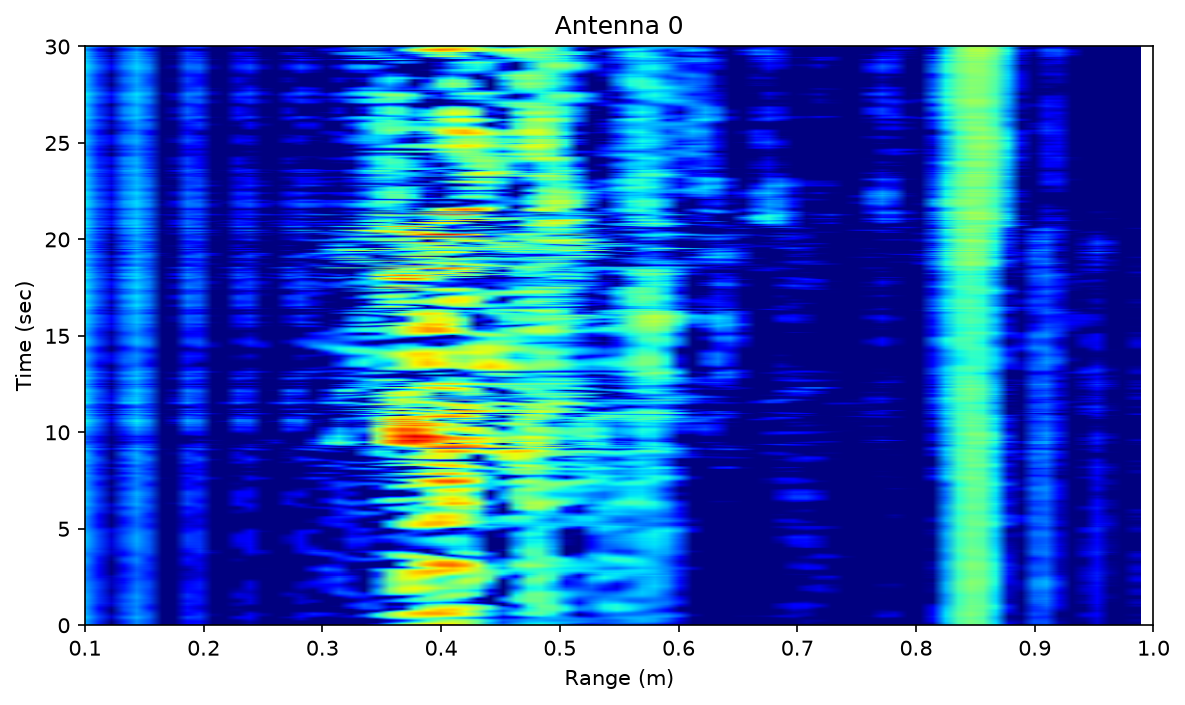

main() 用时:0.691s


In [29]:
main()